# TP2 · Predicción de la tasa de adopción de IA

**Pregunta:** ¿Qué tasa continua de adopción de IA puede estimarse para una empresa y trimestre a partir de país, industria, cantidad de empleados, ingresos, antigüedad y año?

La variable objetivo es `ai_adoption_rate` (0–100). La prueba se separa por `company_id` para evaluar empresas nunca vistas; la validación de Ridge también agrupa por empresa. Se comparan una línea base y tres regresores. Todas las transformaciones se ajustan dentro del pipeline.

In [1]:
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

SEMILLA = 2026
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLOR_BASE, COLOR_LINEA = "#2b5c8f", "#d95f02"

# Encuentra la carpeta del proyecto sin confundirla con la raíz del repositorio.
def encontrar_proyecto():
    for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if base.name == "proyecto_equipo" and (base / "notebooks").is_dir():
            return base
        if (base / "proyecto_equipo" / "notebooks").is_dir():
            return base / "proyecto_equipo"
    raise FileNotFoundError("No se encontró proyecto_equipo/notebooks")

PROYECTO = encontrar_proyecto()
RUTA_PARQUET = PROYECTO / "datos" / "derivados" / "ai_company_adoption_limpio.parquet"
if not RUTA_PARQUET.exists():
    raise FileNotFoundError("Ejecutá antes 02_limpieza_ai.ipynb para generar el Parquet limpio")
SALIDAS = PROYECTO / "salidas"
SALIDAS.mkdir(parents=True, exist_ok=True)
df = pd.read_parquet(RUTA_PARQUET)
assert df.shape == (150_000, 43), f"Dimensiones inesperadas: {df.shape}"
print(f"Dataset: {len(df):,} filas | {df['company_id'].nunique():,} empresas | {RUTA_PARQUET}")

Dataset: 150,000 filas | 10,000 empresas | /Users/agus/Documents/Codex/2026-10-05/https-github-com-taniagorosito-aa-2026/aa-2026-entorno/proyecto_equipo/datos/derivados/ai_company_adoption_limpio.parquet


In [2]:
# Objetivo continuo: tasa de adopción de IA, expresada entre 0 y 100.
objetivo = "ai_adoption_rate"
columnas_categoricas = ["country", "industry"]
columnas_log = ["num_employees", "annual_revenue_usd_millions"]
columnas_escaladas = ["company_age", "survey_year"]
predictores = columnas_log + columnas_escaladas + columnas_categoricas

# Excluimos el identificador y las variables derivadas del objetivo o medidas al mismo tiempo
# que podrían no estar disponibles al estimar adopción (incluida ai_adoption_stage).
X = df[predictores].copy()
y = pd.to_numeric(df[objetivo], errors="raise").astype(float)
grupos = df["company_id"].astype("string")

# Hold-out agrupado: las filas de cada empresa quedan juntas.
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEMILLA)
train_idx, test_idx = next(gss.split(X, y, groups=grupos))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
grupos_train, grupos_test = grupos.iloc[train_idx], grupos.iloc[test_idx]
assert set(grupos_train).isdisjoint(set(grupos_test))
print(f"Entrenamiento: {len(X_train):,} filas / {grupos_train.nunique():,} empresas")
print(f"Prueba: {len(X_test):,} filas / {grupos_test.nunique():,} empresas; empresas compartidas: 0")

Entrenamiento: 119,969 filas / 8,000 empresas
Prueba: 30,031 filas / 2,000 empresas; empresas compartidas: 0


In [3]:
# Cada modelo recibe su propio preprocesador para evitar estado compartido entre pipelines.
def crear_preprocesador():
    preparador_log = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("escalar", StandardScaler()),
    ])
    preparador_escalado = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
    ])
    preparador_categorico = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num_log", preparador_log, columnas_log),
        ("num_std", preparador_escalado, columnas_escaladas),
        ("cat", preparador_categorico, columnas_categoricas),
    ], remainder="drop")

In [4]:
# Línea base: predice la media del conjunto de entrenamiento.
pipe_dummy = Pipeline([("modelo", DummyRegressor(strategy="mean"))])
pipe_dummy.fit(X_train, y_train)

# Ridge: se ajusta alpha mediante validación cruzada agrupada; el test queda reservado.
cv_agrupado = GroupKFold(n_splits=5)
pipe_ridge = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", Ridge()),
])
grid_ridge = GridSearchCV(
    pipe_ridge,
    param_grid={"modelo__alpha": [1.0, 10.0, 50.0, 100.0, 200.0]},
    cv=cv_agrupado,
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    refit=True,
)
grid_ridge.fit(X_train, y_train, groups=grupos_train)
mejor_ridge = grid_ridge.best_estimator_
print(f"Mejor alpha Ridge: {grid_ridge.best_params_['modelo__alpha']}")
print(f"RMSE medio en CV agrupada: {-grid_ridge.best_score_:.3f} puntos")

# Árbol podado y Random Forest acotado para controlar complejidad y varianza.
pipe_tree = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", DecisionTreeRegressor(max_depth=6, min_samples_leaf=50, random_state=SEMILLA)),
])
pipe_tree.fit(X_train, y_train)
pipe_rf = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", RandomForestRegressor(
        n_estimators=100, max_depth=10, min_samples_leaf=20,
        random_state=SEMILLA, n_jobs=2,
    )),
])
pipe_rf.fit(X_train, y_train)
print("Ridge, árbol de decisión y Random Forest entrenados.")

Mejor alpha Ridge: 200.0
RMSE medio en CV agrupada: 13.793 puntos
Ridge, árbol de decisión y Random Forest entrenados.


In [5]:
def evaluar_modelo(nombre, modelo, X_tr, y_tr, X_te, y_te):
    pred_tr = modelo.predict(X_tr)
    pred_te = modelo.predict(X_te)
    mse_tr = mean_squared_error(y_tr, pred_tr)
    mse_te = mean_squared_error(y_te, pred_te)
    return {
        "Modelo": nombre,
        "MSE (Train)": round(mse_tr, 3),
        "MSE (Test)": round(mse_te, 3),
        "RMSE (Train)": round(np.sqrt(mse_tr), 3),
        "RMSE (Test)": round(np.sqrt(mse_te), 3),
        "MAE (Train)": round(mean_absolute_error(y_tr, pred_tr), 3),
        "MAE (Test)": round(mean_absolute_error(y_te, pred_te), 3),
        "R² (Train)": round(r2_score(y_tr, pred_tr), 3),
        "R² (Test)": round(r2_score(y_te, pred_te), 3),
        "Brecha RMSE": round(np.sqrt(mse_te) - np.sqrt(mse_tr), 3),
    }

modelos = [
    ("Baseline (media)", pipe_dummy),
    ("Ridge", mejor_ridge),
    ("Árbol de decisión", pipe_tree),
    ("Random Forest", pipe_rf),
]
df_comparativa = pd.DataFrame([
    evaluar_modelo(nombre, modelo, X_train, y_train, X_test, y_test)
    for nombre, modelo in modelos
])
display(df_comparativa)
df_comparativa.to_csv(SALIDAS / "tabla_comparativa_modelos_tp2.csv", index=False)

# Se selecciona el menor RMSE de prueba entre los tres regresores para la comparación académica.
modelos_por_nombre = dict(modelos)
resumen_modelos = df_comparativa[df_comparativa["Modelo"] != "Baseline (media)"]
mejor_nombre = resumen_modelos.sort_values("RMSE (Test)").iloc[0]["Modelo"]
modelo_seleccionado = modelos_por_nombre[mejor_nombre]
print(f"Modelo con menor RMSE de prueba: {mejor_nombre}")

,Modelo,MSE (Train),MSE (Test),RMSE (Train),RMSE (Test),MAE (Train),MAE (Test),R² (Train),R² (Test),Brecha RMSE
0,Baseline (media),210.946,213.863,14.524,14.624,11.638,11.716,0.000,-0.000,0.100
1,Ridge,189.110,192.843,13.752,13.887,11.025,11.133,0.104,0.098,0.135
2,Árbol de decisión,188.064,191.435,13.714,13.836,10.993,11.074,0.108,0.105,0.122
3,Random Forest,178.014,190.855,13.342,13.815,10.691,11.067,0.156,0.107,0.473


Modelo con menor RMSE de prueba: Random Forest


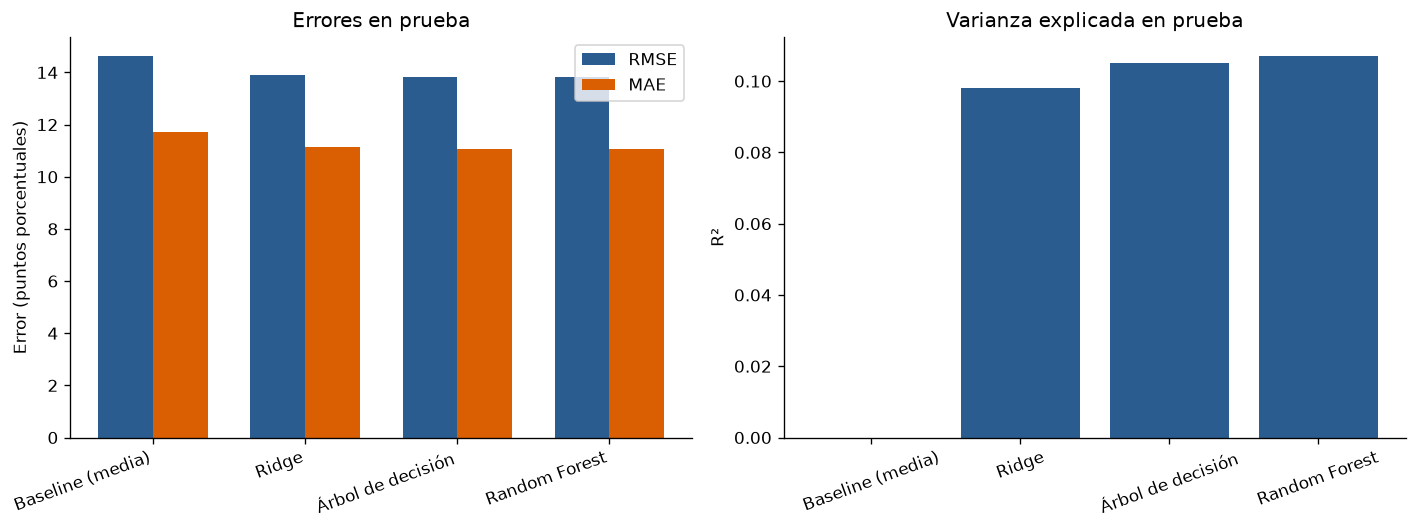

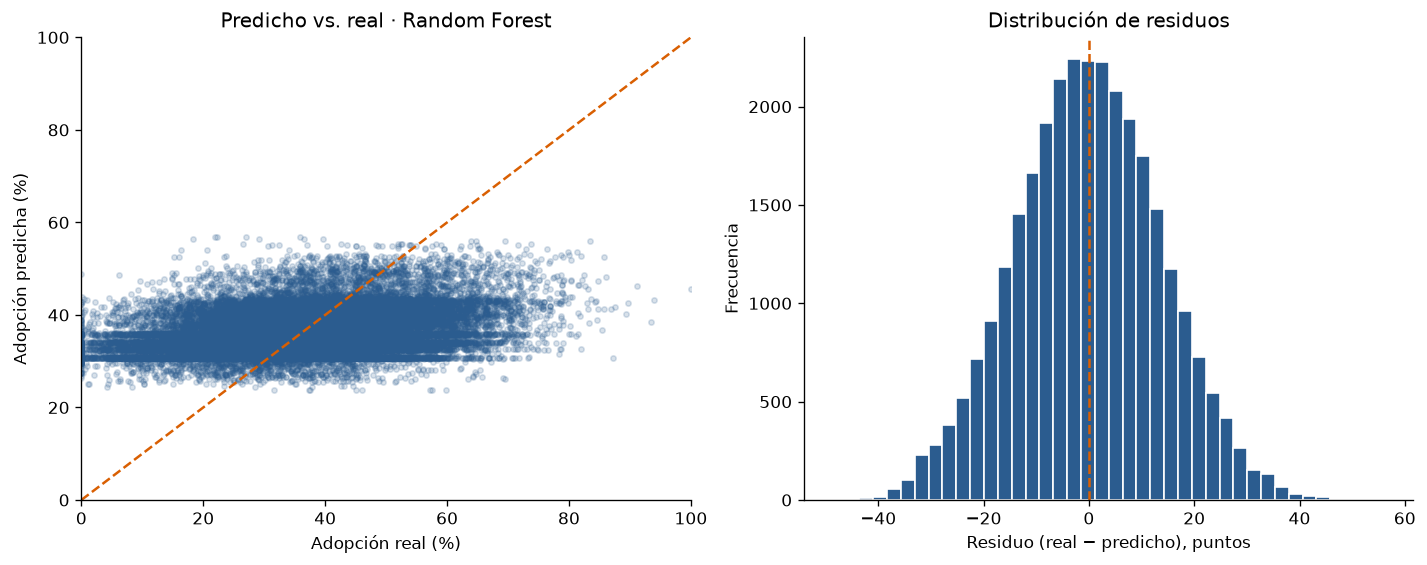

In [6]:
# Comparación de errores (misma unidad) y R² en el conjunto de prueba.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
x = np.arange(len(df_comparativa))
ancho = 0.36
axes[0].bar(x - ancho/2, df_comparativa["RMSE (Test)"], ancho, label="RMSE", color=COLOR_BASE)
axes[0].bar(x + ancho/2, df_comparativa["MAE (Test)"], ancho, label="MAE", color=COLOR_LINEA)
axes[0].set_ylabel("Error (puntos porcentuales)")
axes[0].set_title("Errores en prueba")
axes[0].set_xticks(x, df_comparativa["Modelo"], rotation=20, ha="right")
axes[0].legend()
axes[1].bar(df_comparativa["Modelo"], df_comparativa["R² (Test)"], color=COLOR_BASE)
axes[1].set_ylabel("R²")
axes[1].set_title("Varianza explicada en prueba")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(SALIDAS / "comparativa_metricas_tp2.png", dpi=250, bbox_inches="tight")
plt.show()

# Diagnóstico del modelo elegido según RMSE de prueba.
y_test_pred = modelo_seleccionado.predict(X_test)
residuos = y_test.to_numpy() - y_test_pred
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
ax1.scatter(y_test, y_test_pred, alpha=0.18, color=COLOR_BASE, s=10)
ax1.plot([0, 100], [0, 100], "--", color=COLOR_LINEA, linewidth=1.5)
ax1.set(xlabel="Adopción real (%)", ylabel="Adopción predicha (%)", title=f"Predicho vs. real · {mejor_nombre}", xlim=(0,100), ylim=(0,100))
ax2.hist(residuos, bins=40, color=COLOR_BASE, edgecolor="white")
ax2.axvline(0, color=COLOR_LINEA, linestyle="--")
ax2.set(xlabel="Residuo (real − predicho), puntos", ylabel="Frecuencia", title="Distribución de residuos")
plt.tight_layout()
plt.savefig(SALIDAS / "diagnostico_residuos_tp2.png", dpi=250, bbox_inches="tight")
plt.show()

In [7]:
# Exportar el pipeline elegido y una pequeña muestra de empresas del test para la demo.
modelo_regresion_bundle = {
    "model": modelo_seleccionado,
    "features": predictores,
    "target": objetivo,
    "model_name": mejor_nombre,
    "category_options": {
        "country": sorted(df["country"].dropna().astype(str).unique().tolist()),
        "industry": sorted(df["industry"].dropna().astype(str).unique().tolist()),
    },
}
joblib.dump(modelo_regresion_bundle, SALIDAS / "modelo_regresion_tp2.joblib")
filas_test = df.iloc[test_idx].copy()
demo_reg = filas_test.sample(n=min(8, len(filas_test)), random_state=SEMILLA).copy()
demo_reg.insert(0, "demo_id", [f"REG-{i:02d}" for i in range(1, len(demo_reg)+1)])
demo_reg[["demo_id", "company_id", *predictores, objetivo]].to_csv(
    SALIDAS / "muestras_prueba_regresion.csv", index=False
)
print("Guardados: pipeline seleccionado y muestras de prueba de empresas no vistas.")

Guardados: pipeline seleccionado y muestras de prueba de empresas no vistas.


In [8]:
# Respuestas guiadas a las preguntas de interpretación del TP2.
from IPython.display import Markdown, display

fila_rmse = df_comparativa[df_comparativa["Modelo"] != "Baseline (media)"].sort_values("RMSE (Test)").iloc[0]
fila_mae = df_comparativa[df_comparativa["Modelo"] != "Baseline (media)"].sort_values("MAE (Test)").iloc[0]
fila_r2 = df_comparativa[df_comparativa["Modelo"] != "Baseline (media)"].sort_values("R² (Test)", ascending=False).iloc[0]
gaps = df_comparativa[df_comparativa["Modelo"] != "Baseline (media)"]
mayor_gap = gaps.sort_values("Brecha RMSE", ascending=False).iloc[0]
base_rmse = df_comparativa.loc[df_comparativa["Modelo"] == "Baseline (media)", "RMSE (Test)"].iloc[0]
mejora = (base_rmse - fila_rmse["RMSE (Test)"]) / base_rmse * 100

texto = f"""### Interpretación de resultados

1. **Modelo seleccionado.** {fila_rmse['Modelo']} obtiene el menor RMSE de prueba ({fila_rmse['RMSE (Test)']:.3f} puntos; MSE {fila_rmse['MSE (Test)']:.3f} puntos²). {fila_mae['Modelo']} obtiene el menor MAE ({fila_mae['MAE (Test)']:.3f}) y {fila_r2['Modelo']} el mayor R² ({fila_r2['R² (Test)']:.3f}). La elección depende de si se penalizan más los errores grandes, se prioriza el error absoluto medio o la varianza explicada. El modelo seleccionado reduce el RMSE {mejora:.1f}% frente a la línea base ({base_rmse:.3f}). Las diferencias entre regresores deben evaluarse también por su magnitud práctica.

2. **Ajuste.** La mayor brecha entre RMSE de prueba y entrenamiento corresponde a {mayor_gap['Modelo']} ({mayor_gap['Brecha RMSE']:.3f} puntos). Una brecha positiva indica peor rendimiento en datos no vistos y puede señalar mayor varianza; una brecha pequeña junto con R² bajo sugiere capacidad explicativa limitada o sesgo. La complejidad acotada, regularización y validación agrupada ayudan a controlar la varianza. El gráfico de residuos permite buscar sesgo sistemático y dispersión no constante.

3. **Dominio y residuos.** Los predictores describen estructura y contexto, no toda la dinámica de adopción; las métricas contemporáneas de impacto se excluyeron para reducir fuga. El panel tiene mediciones repetidas por empresa y origen no documentado, por lo que el desempeño solo describe este conjunto. Revisar el gráfico de predicho contra real y los residuos ayuda a detectar patrones que estos predictores no capturan; no permite inferir causalidad.
"""
display(Markdown(texto))

### Interpretación de resultados

1. **Modelo seleccionado.** Random Forest obtiene el menor RMSE de prueba (13.815 puntos; MSE 190.855 puntos²). Random Forest obtiene el menor MAE (11.067) y Random Forest el mayor R² (0.107). La elección depende de si se penalizan más los errores grandes, se prioriza el error absoluto medio o la varianza explicada. El modelo seleccionado reduce el RMSE 5.5% frente a la línea base (14.624). Las diferencias entre regresores deben evaluarse también por su magnitud práctica.

2. **Ajuste.** La mayor brecha entre RMSE de prueba y entrenamiento corresponde a Random Forest (0.473 puntos). Una brecha positiva indica peor rendimiento en datos no vistos y puede señalar mayor varianza; una brecha pequeña junto con R² bajo sugiere capacidad explicativa limitada o sesgo. La complejidad acotada, regularización y validación agrupada ayudan a controlar la varianza. El gráfico de residuos permite buscar sesgo sistemático y dispersión no constante.

3. **Dominio y residuos.** Los predictores describen estructura y contexto, no toda la dinámica de adopción; las métricas contemporáneas de impacto se excluyeron para reducir fuga. El panel tiene mediciones repetidas por empresa y origen no documentado, por lo que el desempeño solo describe este conjunto. Revisar el gráfico de predicho contra real y los residuos ayuda a detectar patrones que estos predictores no capturan; no permite inferir causalidad.
